In [74]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function
import mlgrad.avragg as avragg

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.13.14 (main, Jun 10 2026, 18:10:12) [GCC 15.2.0]


In [75]:
def plot_params(lfm, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    n = lfm.n_input
    plt.plot((0,n), (0,0), ls='--', lw=0.75, color='darkblue')
    mask = np.zeros(n, np.uint8)
    for mod in lfm.models:
        param1 = np.asarray(mod.param[1:])
        # p_max, p_min = param1.max(), param1.min()
        # pp_max = np.full_like(param1, p_max)
        # pp_min = np.full_like(param1, p_min)
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        mask = mask | (abs(param1) > p_threshold)
        # ax.vlines(range(n), pp_min[mask], pp_max[mask], color='gray', alpha=0.25)
        ax.vlines(range(n), param_m, param_p, color='k')
    ax.minorticks_on()
    s = mask.astype("i").sum()
    plt.title(f'#(abs(param) > {p_threshold}) = {s}')


In [76]:
path = f"/home/intellimath/YD/repos/spectra/17"
options = {}
dd = {}
# widgets.load_spectra(path, dd, options)

In [77]:
dd = io.load_spectra(path, {"вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["15"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            # "отсечки_по_молекулярной_массе": ["more100"],                            
                           }, verbose=False)

In [80]:
dd.align_bottom()
dd.crop(400)
# dd.scale_by_mean()

In [70]:
# dd.filter(tau=3.5)

In [78]:
dd.drop_zeros_spectrum()
dd.drop_notfinite()
dd.drop_empty()
dd.isfinite()

In [72]:
# dd.plot_pca_spectra(n_component=5)

In [81]:
dd.plot_spectra(True,kind="despike", tau=3.5, ms=3)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [10]:
# dd.plot_spectra(True, kind="despike", alpha=3.5, tau=1.0, tau_mode=None, ms=0)

In [11]:
# dd.select_baselines(tau2=1.0e5, tau1=-1.0e-3,
#                     func=funcs.RStep(0.00, 0.00), 
#                     func2_e=inventory.relative_abs_max
#                    )

In [12]:
# dd.subtract_baselines(tau2=1.0e4, tau1=-0.0001, 
#                       func=funcs.RStep(0.00, 0.00),
#                       # func2_e=inventory.relative_abs_max,
#                      )

In [13]:
# dd.plot_window_mean_std()

In [14]:
# dd.plot_spectra(True, kind="wh", tau2_smooth=0, n_component=None, ms=1, lw=0)

In [15]:
# dd.select_baselines(tau2=1.0e3, tau2_smooth=0.0, func=funcs.RStep(0.001, eps=0.001), func2_e=inventory.relative_abs_max)

In [16]:
# dd.plot_window_mean_std()

In [17]:
# dd2 = dd.copy()
# dd2.subtract_baselines(tau2=1.0e3, 
#                       func=funcs.RStep(0.01, 0.001),
#                       func2_e=inventory.relative_abs_max,
#                      )

In [18]:
# dd2.plot_window_mean_std()

In [19]:
dd2 = spectra.SpectraCollection()
for key, sp in dd.spectra.items():
    dd2[key] = sp.robust_averaging(tau=3.5)

In [20]:
dd2.isfinite
dd2.drop_notfinite()
dd2.drop_zeros_spectrum()

In [21]:
dd2.filter()

In [22]:
dd2.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [23]:
# dd2.plot_mu_sigma()

In [24]:
# dd2.select_for_exclusion()

In [25]:
# dd2.apply(lambda x, y: np.log(y+1))
# dd2.apply(lambda x, y: y+(y.max()-y.min())/(x.max()-x.min())*(x-x.min()))
# dd2.apply(lambda x, y: np.exp(y)-1)

In [26]:
# dd2.scale_by_max()
dd2.scale_by_mean()

In [27]:
dd2.select_baselines(tau2=1.0e4, #tau1=-0.0001,
                     func=funcs.RStep(0.001, 0.001), 
                     func2_e=inventory.relative_abs_max,                     
                    )

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [ ]:
dd2.subtract_baselines(tau2=1.0e4, #tau1=-0.001,
                      func=funcs.RStep(0.001, 0.001),
                      func2_e=inventory.relative_abs_max,
                     )
dd2.scale_by_mean()

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_1_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_2_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_3_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_1_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_2_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_3_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__15_5_1_1_термический_20260420_super_SE__H2O(…

In [ ]:
# dd2.save("/home/intellimath/work/spectra/17_termo", "rm_bl")

In [3]:
dd2 = spectra.SpectraCollection()
dd2.load("/home/intellimath/work/spectra/17_termo", "rm_bl")

In [4]:
dd2.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [5]:
# dd2.plot_window_mean_std()

In [6]:
dd_SA = dd2.subcollection_by_attr_value("вид_бактерий", "SA")
dd_SS = dd2.subcollection_by_attr_value("вид_бактерий", "SS")
dd_SH = dd2.subcollection_by_attr_value("вид_бактерий", "SH")

Ys_SA = dd_SA.union_y()
Ys_SS = dd_SS.union_y()
Ys_SH = dd_SH.union_y()
Ys = dd2.union_y()
print(len(Ys_SA), len(Ys_SS), len(Ys_SH))

59 59 58


In [7]:
# dd_SA.plot_pca_spectra()

In [8]:
# dd_SA.plot_spectra(False)

In [9]:
# dd2.plot_mu_sigma()

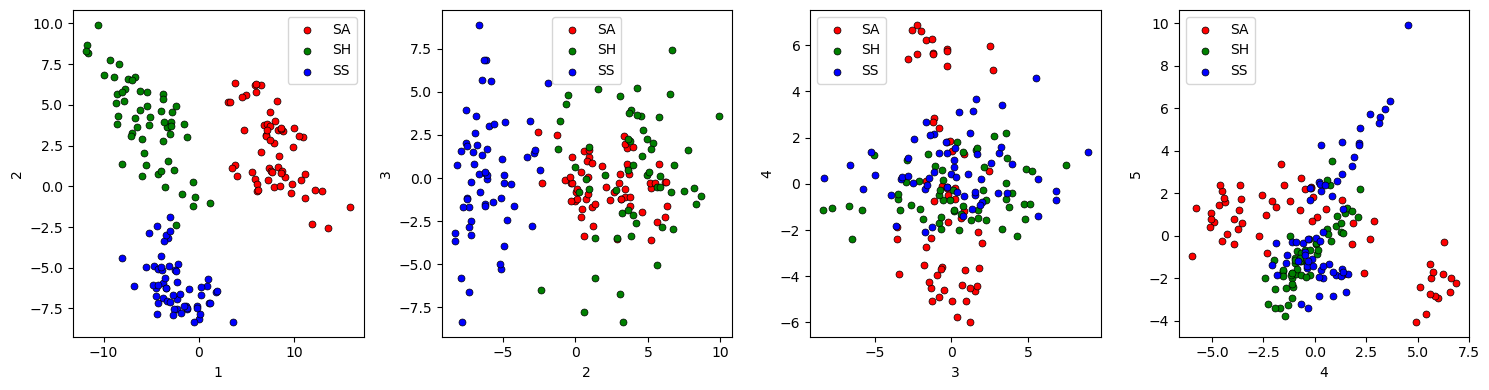

In [10]:
c, As, Ls = pca.find_loc_and_pc(Ys, 5)
U = (Ys - c) @ As.T
U_SA = (Ys_SA - c) @ As.T
U_SS = (Ys_SS - c) @ As.T
U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

# Ls /= Ls.sum()
# plt.figure(figsize=(10,3))
# plt.plot(Ls, marker='o')
# plt.grid(ls=':', lw=0.5)
# plt.minorticks_on()
# plt.show()

In [11]:
# dd2.plot_spectra()

In [12]:
# dd2.plot_mu_sigma()

In [13]:
import mlgrad.models as models
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss

import mlgrad.regr as regr
import mlgrad.af as af

Zs_SS = np.ones(Ys_SS.shape[0])
Zs_SH = np.ones(Ys_SH.shape[0])
Zs_SA = np.ones(Ys_SA.shape[0])

ys = np.concatenate((Ys_SS, Ys_SH, Ys_SA), axis=0)
zs = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA), axis=0)

ys1 = np.concatenate((Ys_SS,Ys_SH), axis=0)
zs1 = np.concatenate((Zs_SS,-Zs_SH), axis=0)
ys1 = np.ascontiguousarray(ys1)
zs1 = np.ascontiguousarray(zs1)

ys2 = np.concatenate((Ys_SH,Ys_SA), axis=0)
zs2 = np.concatenate((Zs_SH,-Zs_SA), axis=0)
ys2 = np.ascontiguousarray(ys2)
zs2 = np.ascontiguousarray(zs2)

ys3 = np.concatenate((Ys_SA,Ys_SS), axis=0)
zs3 = np.concatenate((Zs_SA,-Zs_SS), axis=0)
ys3 = np.ascontiguousarray(ys3)
zs3 = np.ascontiguousarray(zs3)

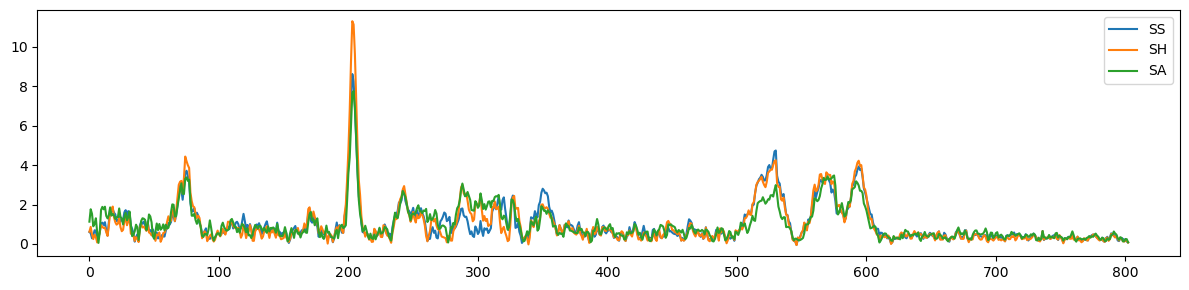

In [14]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
import joblib

@joblib.delayed
#@joblib.wrap_non_picklable_objects
def fit_snm(ys, zs, weights, tau=0, accuracy_min=0.75, n_try=5, sigma=10.0, p_threshold=1.0e-4):
    mod = models.SigmaNeuronModel(funcs.Sigmoidal(sigma), ys.shape[1])
    mod.allocate()
    mod.init_param()
    mod.use_regularizer(funcs2.AbsoluteNorm(), tau)

    if p_threshold != 0:
        projector = gd.Masked(mod, p_threshold)
    else:
        projector = None

    for _ in range(n_try):
        mod.init_param()

        alg = regr.regression(ys, zs, mod,
                              loss_func=loss.ErrorLoss(funcs.SoftAbs_Sqrt(0.01)),
                              # loss_func=loss.ErrorLoss(funcs.Abs()),
                              # loss_func=loss.ErrorLoss(funcs.Square()),
                              projector=projector, 
                              weights=weights,
                              h=0.003, n_iter=1000)
        w = accuracy_score(zs, np.sign(mod.evaluate(ys)))
        if w >= accuracy_min:
            break
    return mod, w

def fit_lfm(ys, zs, tau=0, *, n_model=45, accuracy_min=0.75, n_try=5, sigma=10.0, p_threshold=1.0e-4):
    Np = (zs>0).sum()
    Nm = (zs<0).sum()
    N = Np + Nm
    
    weights = np.zeros(N)
    weights[zs > 0] = Nm / N
    weights[zs < 0] = Np / N

    with joblib.Parallel(n_jobs=4, max_nbytes=None, batch_size=1) as parallel:
        results = parallel( 
            [fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma) for i in range(n_model)]
        )

    lfm = models.LinearFuncModel()
    for mod, w in results:
    # for i in range(n_model):
    #     mod, w = fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma, p_threshold=p_threshold)
        lfm.add(mod, w)

    inventory.normalize(lfm.weights.asarray())
    return lfm

#### SS/SH

In [20]:
lfm1 = fit_lfm(ys1, zs1, tau=300.0)
print(accuracy_score(zs1, np.sign(lfm1.evaluate(ys1))))

0.9658119658119658


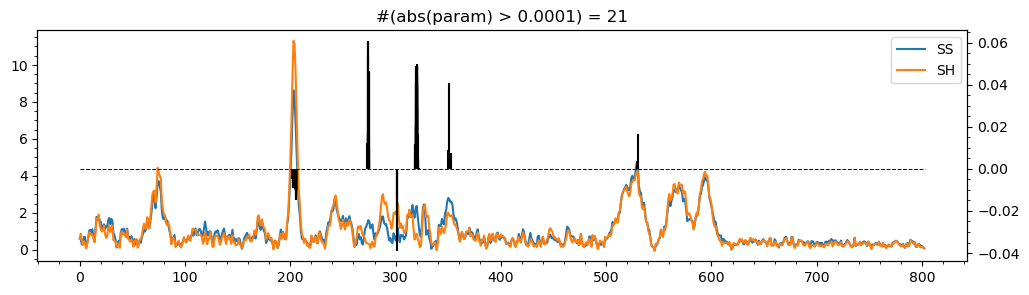

In [21]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.minorticks_on()
plt.legend()
plot_params(lfm1)
plt.show()
# print(np.asarray(lfm1.models[0].param))

In [22]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm1, ys1, zs1)

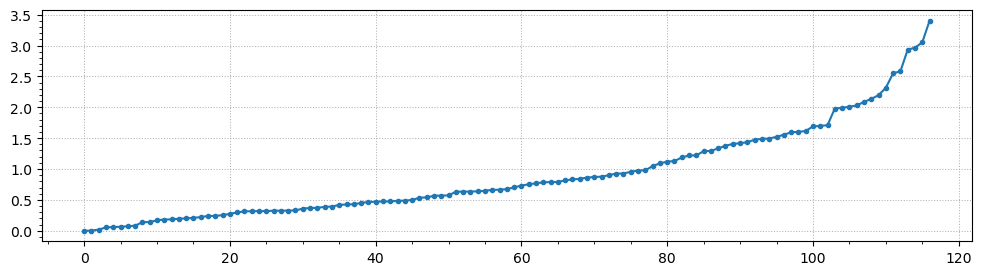

In [23]:
plt.figure(figsize=(12,3))
plt.plot(sorted(abs(inventory.modified_zscore(zs1*lfm1.evaluate(ys1)))), marker='o', ms=3)
plt.grid(ls=':', lw=0.75)
plt.minorticks_on()
plt.show()

### SH / SA

In [24]:
lfm2 = fit_lfm(ys2, zs2, tau=350.0)
print(accuracy_score(zs2, np.sign(lfm2.evaluate(ys2))))

0.9743589743589743


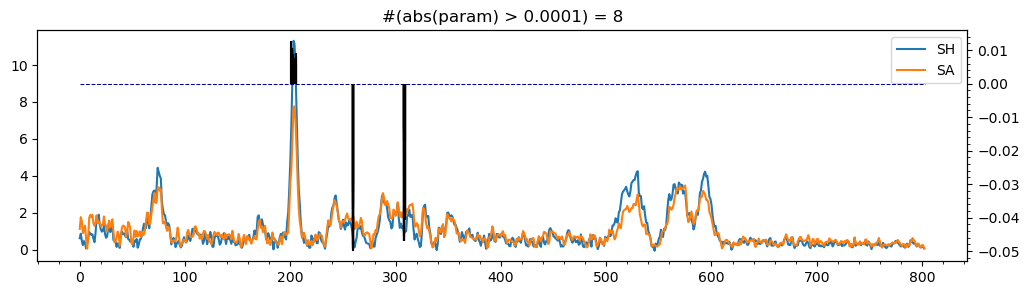

In [25]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plot_params(lfm2)
plt.show()

In [26]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm2, ys2, zs2)

In [27]:
# plt.figure(figsize=(12,3))
# plt.plot(sorted(abs(inventory.modified_zscore(zs2*lfm2.evaluate(ys2)))), marker='o', ms=3)
# # plt.plot(sorted(zs2*lfm2.evaluate(ys2)), marker='o', ms=3)
# plt.grid(ls=':', lw=0.75)
# plt.minorticks_on()
# plt.show()

### SA / SS

In [31]:
lfm3 = fit_lfm(ys3, zs3, tau=500)
print(accuracy_score(zs3, np.sign(lfm3.evaluate(ys3))))

0.9745762711864406


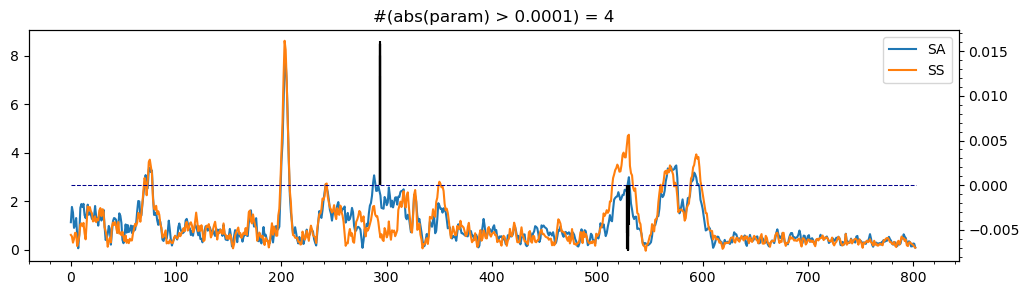

In [32]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.legend()
plot_params(lfm3)
plt.show()

In [33]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm3, ys3, zs3)

In [34]:
# plt.figure(figsize=(12,3))\
# plt.plot(sorted(abs(inventory.modified_zscore(zs3*lfm3.evaluate(ys3)))), marker='o', ms=3)
# plt.grid(ls=':', lw=0.75)
# plt.minorticks_on()
# plt.show()

176
56
65
116


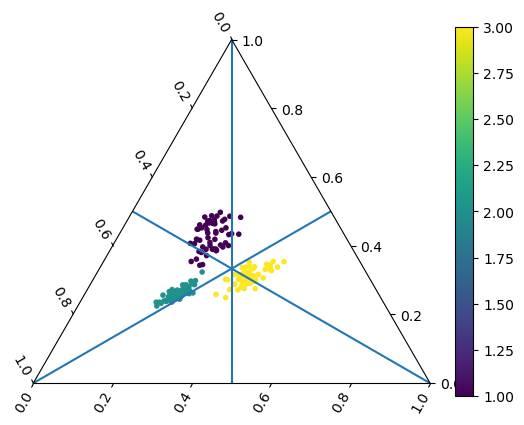

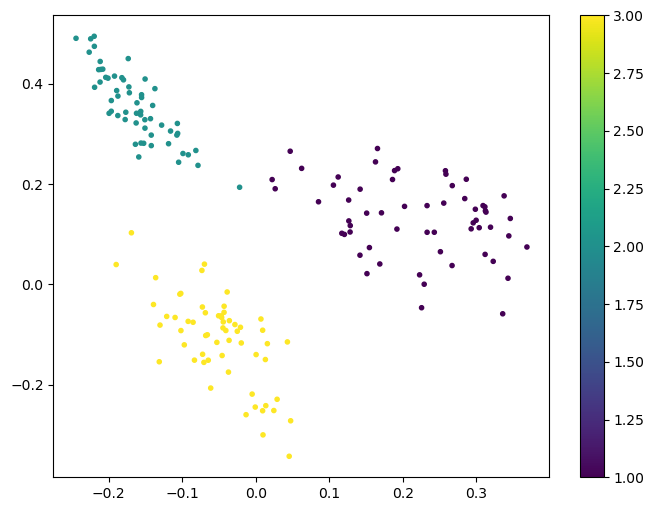

In [35]:
import mpltern
print(len(ys))

ax = plt.subplot(projection="ternary")
Z1 = lfm1.evaluate(ys) # SS/SH
Z2 = lfm2.evaluate(ys) # SH/SA
Z3 = lfm3.evaluate(ys) # SA/SS
Y1 = (1 + (Z1 - Z3) / 2) / 2
Y2 = (1 + (Z2 - Z1) / 2) / 2
Y3 = (1 + (Z3 - Z2) / 2) / 2
Y1[Y1<0] = 0
Y2[Y2<0] = 0
Y3[Y3<0] = 0
print(((Z1>0) & (Z3<0)).sum())
print(((Z2>0) & (Z1<0)).sum())
print(((Z2>0) & (Z3<0)).sum())
# print(Y1)
# print(Y2)
# print(Y3)
C = [(y1,y2,y3) for y1,y2,y3 in zip(Y1,Y2,Y3)]
# cax = ax.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax.transAxes)
cs = ax.scatter(Y1, Y2, Y3, c=zs, s=9)
plt.colorbar(cs)
ax.axline(
    [0.5, 0.0, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.5, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.0, 0.5],
    [0.5, 0.5, 0.5])
plt.show()

zz1 = Y1
zz2 = Y2 * np.exp(2j/3 * np.pi)
zz3 = Y3 * np.exp(-2j/3 * np.pi)
C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
plt.figure(figsize=(8,6))
cs = plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=9, c=C)
plt.colorbar(cs)
plt.show()


In [36]:
def cls_predict(ys):
    Z1 = lfm1.evaluate(ys) # SS/SH
    Z2 = lfm2.evaluate(ys) # SH/SA
    Z3 = lfm3.evaluate(ys) # SA/SS
    s0 = Z1 - Z3
    s1 = Z2 - Z1
    s2 = Z3 - Z2
    ss = np.c_[s0,s1,s2]
    return np.argmax(ss, axis=1)

In [37]:
# print(np.c_[zs-1,cls_predict(ys)])
print(accuracy_score(zs-1, cls_predict(ys)))

0.9318181818181818


## 

In [38]:
from sklearn.linear_model import LogisticRegression

XX = np.c_[np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3)]
YY = np.concatenate((Zs_SS-1, Zs_SH, 2*Zs_SA))

lrg = LogisticRegression()
lrg.fit(XX, YY)

print(accuracy_score(YY, lrg.predict(XX)))

1.0


In [39]:
from sklearn.neural_network import MLPClassifier
nn = MLPClassifier((100,100,100), activation="tanh", max_iter=1000)
nn.fit(XX, YY)
print(accuracy_score(YY, nn.predict(XX)))

1.0


In [42]:
path = f"/home/intellimath/YD/repos/spectra/19"
dd_test = io.load_spectra(path, {"вид_бактерий":["A", "B", "C", "D"], 
                            # "номер_цикла":["1"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            # "отсечки_по_молекулярной_массе": ["more100"],                            
                           }, verbose=False)

In [43]:
dd_test.align_bottom()
dd_test.crop(400)
dd_test.scale_by_mean()

In [44]:
dd_test.filter(tau=3.5)

In [45]:
dd_test.drop_zeros_spectrum()
dd_test.drop_notfinite()
dd_test.drop_empty()
dd_test.isfinite()

In [46]:
dd2_test = spectra.SpectraCollection()
for key, sp in dd_test.spectra.items():
    dd2_test[key] = sp.robust_averaging(tau=3.5)

In [47]:
dd2_test.isfinite
dd2_test.drop_notfinite()
dd2_test.drop_zeros_spectrum()

In [48]:
# dd2.scale_by_max()
dd2_test.scale_by_mean()

In [49]:
dd2_test.filter()

In [52]:
dd2_test.select_baselines(tau2=1.0e4, #tau1=-0.0001,
                     func=funcs.RStep(0.001, 0.001), 
                     func2_e=inventory.relative_abs_max,                     
                    )

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('A_no date__18…

In [53]:
dd2_test.subtract_baselines(tau2=1.0e4, #tau1=-0.001,
                      func=funcs.RStep(0.001, 0.001),
                      func2_e=inventory.relative_abs_max,
                     )
dd2_test.scale_by_mean()

FloatProgress(value=0.0, bar_style='success', description='A_no date__18_Test_no date_1_термический_20260602_s…

FloatProgress(value=0.0, bar_style='success', description='A_no date__18_Test_no date_2_термический_20260602_s…

FloatProgress(value=0.0, bar_style='success', description='A_no date__18_Test_no date_3_термический_20260602_s…

FloatProgress(value=0.0, bar_style='success', description='B_no date__18_Test_no date_1_термический_20260602_s…

FloatProgress(value=0.0, bar_style='success', description='B_no date__18_Test_no date_2_термический_20260602_s…

...

FloatProgress(value=0.0, bar_style='success', description='C_no date__18_Test_no date_2_термический_20260602_s…

FloatProgress(value=0.0, bar_style='success', description='C_no date__18_Test_no date_3_термический_20260602_s…

FloatProgress(value=0.0, bar_style='success', description='D_no date__18_Test_no date_1_термический_20260602_s…

FloatProgress(value=0.0, bar_style='success', description='D_no date__18_Test_no date_2_термический_20260602_s…

FloatProgress(value=0.0, bar_style='success', description='D_no date__18_Test_no date_3_термический_20260602_s…

In [54]:
dd2_test.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('A_no date__18…

In [55]:
dd_A = dd2_test.subcollection_by_attr_value("вид_бактерий", "A")
dd_B = dd2_test.subcollection_by_attr_value("вид_бактерий", "B")
dd_C = dd2_test.subcollection_by_attr_value("вид_бактерий", "C")
dd_D = dd2_test.subcollection_by_attr_value("вид_бактерий", "D")

Ys_A = dd_A.union_y()
Ys_B = dd_B.union_y()
Ys_C = dd_C.union_y()
Ys_D = dd_D.union_y()
Ys = dd2_test.union_y()
print(len(Ys_A), len(Ys_B), len(Ys_C), len(Ys_D))

30 29 29 30


In [56]:
Z1_A = lfm1.evaluate(Ys_A)
Z2_A = lfm2.evaluate(Ys_A)
Z3_A = lfm3.evaluate(Ys_A)
Y1_A = (1 + (Z1_A - Z3_A) / 2) / 2
Y2_A = (1 + (Z2_A - Z1_A) / 2) / 2
Y3_A = (1 + (Z3_A - Z2_A) / 2) / 2
Y1_A[Y1_A<0] = 0
Y2_A[Y2_A<0] = 0
Y3_A[Y3_A<0] = 0
zz1_A = Y1_A
zz2_A = Y2_A * np.exp(2j/3 * np.pi)
zz3_A = Y3_A * np.exp(-2j/3 * np.pi)
XX_A = np.c_[np.real(zz1_A+zz2_A+zz3_A), np.imag(zz1_A+zz2_A+zz3_A)]

In [57]:
YY_A = lrg.predict(XX_A)
print(YY_A)

[2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2.]


In [58]:
Z1_B = lfm1.evaluate(Ys_B)
Z2_B = lfm2.evaluate(Ys_B)
Z3_B = lfm3.evaluate(Ys_B)
Y1_B = (1 + (Z1_B - Z3_B) / 2) / 2
Y2_B = (1 + (Z2_B - Z1_B) / 2) / 2
Y3_B = (1 + (Z3_B - Z2_B) / 2) / 2
Y1_B[Y1_B<0] = 0
Y2_B[Y2_B<0] = 0
Y3_B[Y3_B<0] = 0
zz1_B = Y1_B
zz2_B = Y2_B * np.exp(2j/3 * np.pi)
zz3_B = Y3_B * np.exp(-2j/3 * np.pi)
XX_B = np.c_[np.real(zz1_B+zz2_B+zz3_B), np.imag(zz1_B+zz2_B+zz3_B)]

In [59]:
YY_B = lrg.predict(XX_B)
print((YY_B ==0).sum(), (YY_B ==1).sum(), (YY_B ==2).sum())

0 1 28


In [60]:
Z1_C = lfm1.evaluate(Ys_C)
Z2_C = lfm2.evaluate(Ys_C)
Z3_C = lfm3.evaluate(Ys_C)
Y1_C = (1 + (Z1_C - Z3_C) / 2) / 2
Y2_C = (1 + (Z2_C - Z1_C) / 2) / 2
Y3_C = (1 + (Z3_C - Z2_C) / 2) / 2
Y1_C[Y1_C<0] = 0
Y2_C[Y2_C<0] = 0
Y3_C[Y3_C<0] = 0
zz1_C = Y1_C
zz2_C = Y2_C * np.exp(2j/3 * np.pi)
zz3_C = Y3_C * np.exp(-2j/3 * np.pi)
XX_C = np.c_[np.real(zz1_C+zz2_C+zz3_C), np.imag(zz1_C+zz2_C+zz3_C)]

In [61]:
YY_C = lrg.predict(XX_C)
print(YY_C)

[2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2.]


In [62]:
Z1_D = lfm1.evaluate(Ys_D)
Z2_D = lfm2.evaluate(Ys_D)
Z3_D = lfm3.evaluate(Ys_D)
Y1_D = (1 + (Z1_D - Z3_D) / 2) / 2
Y2_D = (1 + (Z2_D - Z1_D) / 2) / 2
Y3_D = (1 + (Z3_D - Z2_D) / 2) / 2
Y1_D[Y1_D<0] = 0
Y2_D[Y2_D<0] = 0
Y3_D[Y3_D<0] = 0
zz1_D = Y1_D
zz2_D = Y2_D * np.exp(2j/3 * np.pi)
zz3_D = Y3_D * np.exp(-2j/3 * np.pi)
XX_D = np.c_[np.real(zz1_D+zz2_D+zz3_D), np.imag(zz1_D+zz2_D+zz3_D)]

In [63]:
YY_D = lrg.predict(XX_D)
print(YY_D)

[2. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]


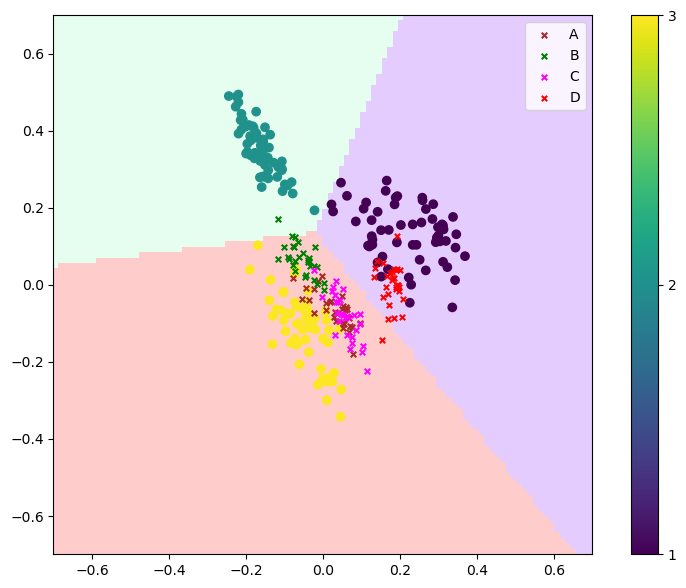

In [64]:
Zs_A = np.ones(Ys_A.shape[0])
Zs_B = np.ones(Ys_B.shape[0])
Zs_C = np.ones(Ys_C.shape[0])
Zs_D = np.ones(Ys_D.shape[0])

C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
plt.figure(figsize=(10,7))
xx, yy = np.meshgrid(np.linspace(-0.7, 0.7, 100), np.linspace(-0.7, 0.7, 100))
xy = np.c_[xx.ravel(), yy.ravel()]
zz = lrg.predict(xy)
zz = zz.reshape(xx.shape)
plt.imshow(zz, alpha=0.2, cmap=plt.cm.rainbow, extent=(-0.7,0.7,-0.7,0.7), origin="lower")

cs=plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=36, c=C)
plt.colorbar(cs, ticks=[1,2,3])
plt.scatter(np.real(zz1_A+zz2_A+zz3_A), np.imag(zz1_A+zz2_A+zz3_A), s=16, marker='x', c="brown", label="A")
plt.scatter(np.real(zz1_B+zz2_B+zz3_B), np.imag(zz1_B+zz2_B+zz3_B), s=16, marker='x', c="green", label="B")
plt.scatter(np.real(zz1_C+zz2_C+zz3_C), np.imag(zz1_C+zz2_C+zz3_C), s=16, marker='x', c="magenta", label="C")
plt.scatter(np.real(zz1_D+zz2_D+zz3_D), np.imag(zz1_D+zz2_D+zz3_D), s=15, marker='x', c="red", label="D")
plt.legend()
plt.show()
